# CRISP-DM phase 2 : Data Understanding, D8 (Early Stage Diabetes Risk Prediction, UCI)

Responsable : Omar (diabète)

**À surveiller :** 520 patients hospitaliers, 16 prédicteurs (Age + 15 symptômes binaires Yes/No). Très fort taux de doublons (269 doublons sur 520 lignes, >51%). Variables Yes/No à encoder numériquement.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import load, REGISTRY

DS = 'D8'
df, target = load(DS)   # vérifie aussi la taille face au tableau 2 de l'article
REGISTRY[DS]['name'], df.shape

[D8] lignes=520 pos=320 neg=200 | article: lignes=520 pos=320 neg=200 -> OK


('Early Stage Diabetes Risk Prediction', (520, 17))

## 1. Structure et dictionnaire des variables
Compléter le tableau dans le rapport : nom, signification médicale, type, unité.

In [2]:
df.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,1
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,1
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,1
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,1
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,1


In [3]:
pd.DataFrame({'dtype': df.dtypes, 'n_unique': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

,dtype,n_unique,min,max
Age,int64,51,16.0,90.0
Alopecia,str,2,NaN,NaN
Gender,str,2,NaN,NaN
Genital thrush,str,2,NaN,NaN
Irritability,str,2,NaN,NaN
Itching,str,2,NaN,NaN
Obesity,str,2,NaN,NaN
Polydipsia,str,2,NaN,NaN
Polyphagia,str,2,NaN,NaN
Polyuria,str,2,NaN,NaN


## 2. Variable cible

class
0    200
1    320
Name: count, dtype: int64 
 class
0    0.385
1    0.615
Name: count, dtype: float64


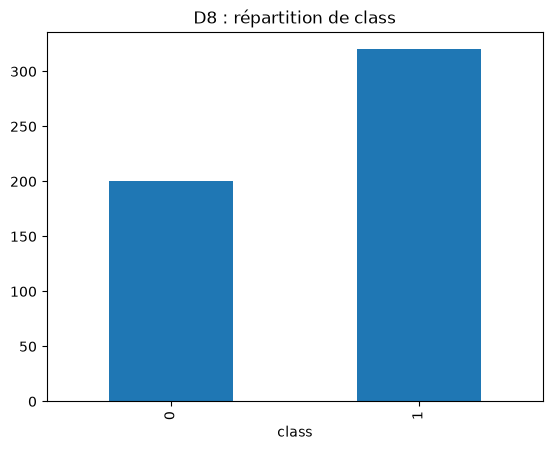

In [4]:
counts = df[target].value_counts().sort_index()
print(counts, '\n', (counts / len(df)).round(3))
counts.plot.bar(title=f'{DS} : répartition de {target}')
plt.show()

## 3. Valeurs manquantes (vraies et codées)

In [5]:
print('Valeurs nulles explicites :')
print(df.isna().sum()[df.isna().sum() > 0])

# Zéros médicalement impossibles (spécifique au diabète)
for c in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    if c in df:
        z = (df[c] == 0).sum()
        print(f'{c} = 0 : {z} ({z / len(df) * 100:.1f}%)')

Valeurs nulles explicites :
Series([], dtype: int64)


## 4. Doublons
L'article ne dit pas les avoir supprimés : on les **garde** pour reproduire ses résultats, puis on relance avec `--dedup` pour mesurer leur effet.

In [6]:
n_dup = df.duplicated().sum()
print(f'{n_dup} doublons sur {len(df)} lignes ({n_dup / len(df) * 100:.1f}%) -> {len(df) - n_dup} lignes uniques')
print('Répartition de la cible après déduplication :')
print(df.drop_duplicates()[target].value_counts())

269 doublons sur 520 lignes (51.7%) -> 251 lignes uniques
Répartition de la cible après déduplication :
class
1    173
0     78
Name: count, dtype: int64


## 5. Statistiques descriptives et distributions

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,520.0,48.03,12.15,16.0,39.0,47.5,57.0,90.0
class,520.0,0.62,0.49,0.0,0.0,1.0,1.0,1.0


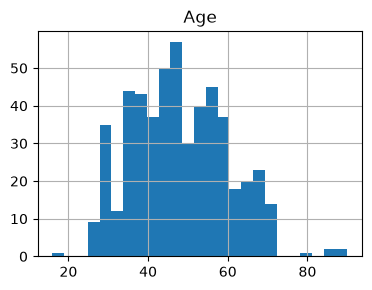

In [8]:
num = [c for c in df.columns if c != target and pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 5]
if num:
    df[num].hist(bins=25, figsize=(14, 3 * ((len(num) + 3) // 4)), layout=(-1, 4))
    plt.tight_layout()
    plt.show()
else:
    print('Pas de variables numériques continues (> 5 modalités)')

## 6. Valeurs aberrantes (méthode IQR)
Interpréter médicalement : erreur de saisie ou patient réellement extrême ?

In [9]:
if num:
    q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
    print(outliers[outliers > 0])
else:
    print('Aucune variable numérique continue')

Age    4
dtype: int64


## 7. Variables selon la classe

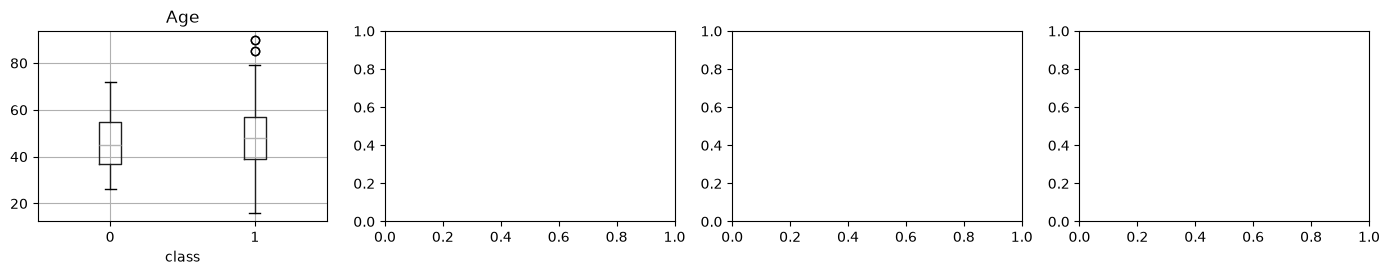

In [10]:
if num:
    fig, axes = plt.subplots((len(num) + 3) // 4, 4, figsize=(14, 3 * ((len(num) + 3) // 4)))
    for ax, c in zip(axes.flat, num):
        df.boxplot(column=c, by=target, ax=ax)
    plt.suptitle('')
    plt.tight_layout()
    plt.show()

In [11]:
cat = [c for c in df.columns if c != target and (df[c].nunique() <= 5 or not pd.api.types.is_numeric_dtype(df[c]))]
for c in cat[:10]:
    print(f'=== {c} vs {target} ===')
    print(pd.crosstab(df[c], df[target], normalize='index').round(2), '\n')

=== Gender vs class ===
class      0     1
Gender            
Female  0.10  0.90
Male    0.55  0.45 

=== Polyuria vs class ===
class        0     1
Polyuria            
No        0.71  0.29
Yes       0.06  0.94 

=== Polydipsia vs class ===


class          0     1
Polydipsia            
No          0.67  0.33
Yes         0.03  0.97 

=== sudden weight loss vs class ===
class                  0     1
sudden weight loss            
No                  0.56  0.44
Yes                 0.13  0.87 

=== weakness vs class ===
class        0     1
weakness            
No        0.53  0.47
Yes       0.29  0.71 

=== Polyphagia vs class ===
class          0     1
Polyphagia            
No          0.54  0.46
Yes         0.20  0.80 

=== Genital thrush vs class ===
class              0     1
Genital thrush            
No              0.41  0.59
Yes             0.28  0.72 

=== visual blurring vs class ===
class               0     1
visual blurring            
No               0.49  0.51
Yes              0.25  0.75 

=== Itching vs class ===
class       0     1
Itching            
No       0.38  0.62
Yes      0.39  0.61 

=== Irritability vs class ===
class            0     1
Irritability            
No            0.47  0.53
Yes      

## 8. Corrélations

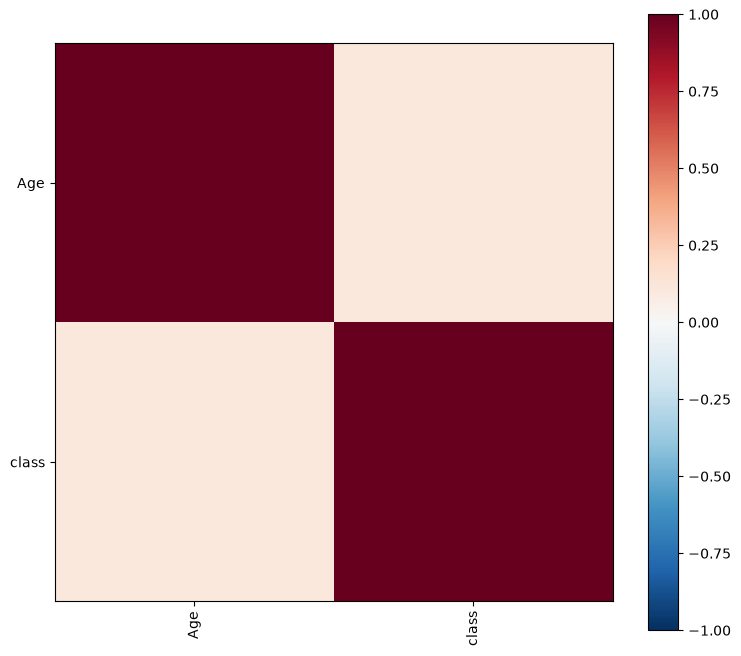

Corrélations avec la cible :
Age    0.109
Name: class, dtype: float64


In [12]:
corr = df.select_dtypes('number').corr()
if len(corr) > 1:
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.columns)
    plt.colorbar(im)
    plt.show()
    if target in corr.columns:
        print('Corrélations avec la cible :')
        print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3))

## 9. Conclusions pour la préparation (phase 3)

- Variables à encoder : 15 colonnes textuelles Yes/No ('Polyuria', 'Polydipsia', etc.) et 'Gender' ('Male'/'Female').
- Valeurs manquantes / codées à traiter : aucune valeur manquante apparente. Pas de zéros anormaux dans l'âge.
- Doublons : 269 doublons (51.7% du jeu de données !). Ils sont conservés pour reproduire les résultats de l'article, puis supprimés avec `--dedup` pour évaluer la sur-estimation.
- Normalisation : StandardScaler inclus dans le Pipeline sklearn.